# Avance 3 — Modelado Supervisado, Evaluación de Errores y Explicabilidad (XAI)
**Proyecto:** Inteligencia Judicial y Eficiencia Procesal en Tribunales de Familia (C.A. de Valparaíso, 2015–2025) · **Equipo EMCR**

Este cuaderno reproducible implementa íntegramente el **Avance 3** ciñéndose estrictamente a la metodología de **Taller 5 (`Clase 06 - Modelos`)** y **Taller 6 (`Clase 07 - Validación, Bootstrap y XAI`)**:
1. **Formulación del problema predictivo ($X, y, T$)** y control riguroso de fuga de información (*Zero Data Leakage*).
2. **Partición temporal por cambio de régimen estructural** (`Train: 2021–2023` vs `Test Out-of-Time: 2024–2025`) y validación cruzada estratificada de 5 folds (`StratifiedKFold`) con `Pipeline`.
3. **Comparación de familias de algoritmos**: Línea base (`DummyClassifier`), modelo lineal paramétrico (`LogisticRegression`), ensamble *bagging* (`RandomForestClassifier`) y ensambles *boosting* (`XGBClassifier`, `CatBoostClassifier`).
4. **Evaluación de errores, curvas ROC y Precision–Recall, calibración de umbral jurídico ($0.50 \rightarrow 0.35$) e incertidumbre mediante Bootstrap ($B=500$)** sobre el conjunto de prueba.
5. **Explicabilidad Global (`shap.plots.beeswarm`) y Local (`shap.plots.waterfall` en 3 casos concretos)**, más visualización pedagógica de un árbol de decisión individual (`max_depth=3`).

## 1. Motivación Jurídica, Definición de $X$, $y$, Instante $T$ y Hallazgos del EDA
- **Problema de negocio en estudios jurídicos:** En los Juzgados de Familia (Ley N° 19.968, Arts. 59 y 61), el plazo legal para celebrar audiencia es de 30 días hábiles, pero en la práctica existe una fuerte dispersión (0 a 339 días hábiles). Un estudio jurídico que cotiza honorarios a suma alzada o planifica cautelares sin prever una **Congestión Severa ($> 60$ días hábiles, más del doble del plazo legal)** asume pérdidas económicas y riesgo procesal para su cliente.
- **Instante de predicción ($T$):** Exactamente en `FECHA_PROGRAMACION` (cuando el tribunal dicta la resolución que fija la audiencia).
- **Variable Objetivo ($y$):** `Y_SEVERA = 1` si `PLAZO_AGENDAMIENTO > 60` días hábiles (Lunes a Sábado); `0` en caso contrario.
- **Predictores válidos en $T$ ($X$):** `TRIBUNAL_CORTO` (15 tribunales), `TIPO_AUDIENCIA`, `TIPO_PROCEDIMIENTO`, `MACRO_MATERIA`, `VIDEOCONFERENCIA_INT`, `ORDEN_AUDIENCIA_CAUSA`, `MES_PROG` y `DIA_SEM_PROG`.
- **Exclusión por Fuga (*Data Leakage*):** Se descartan `DIAS_TRAMITACION_PREVIA`, `FECHA_AUDIENCIA`, `DURACION_MINUTOS`, `FLG_AUDIENCIA_FRUSTRADA` y `TOTAL_AUDIENCIAS_CAUSA` porque contienen información futura posterior a $T$.

Total audiencias auditadas: 466,178 (280,795 causas únicas RIT)
Train Régimen Vigente (2021-2023): 130,057 filas | Prevalencia Y=1: 0.2343
Test Out-of-Time (2024-2025):      83,410 filas | Prevalencia Y=1: 0.1559


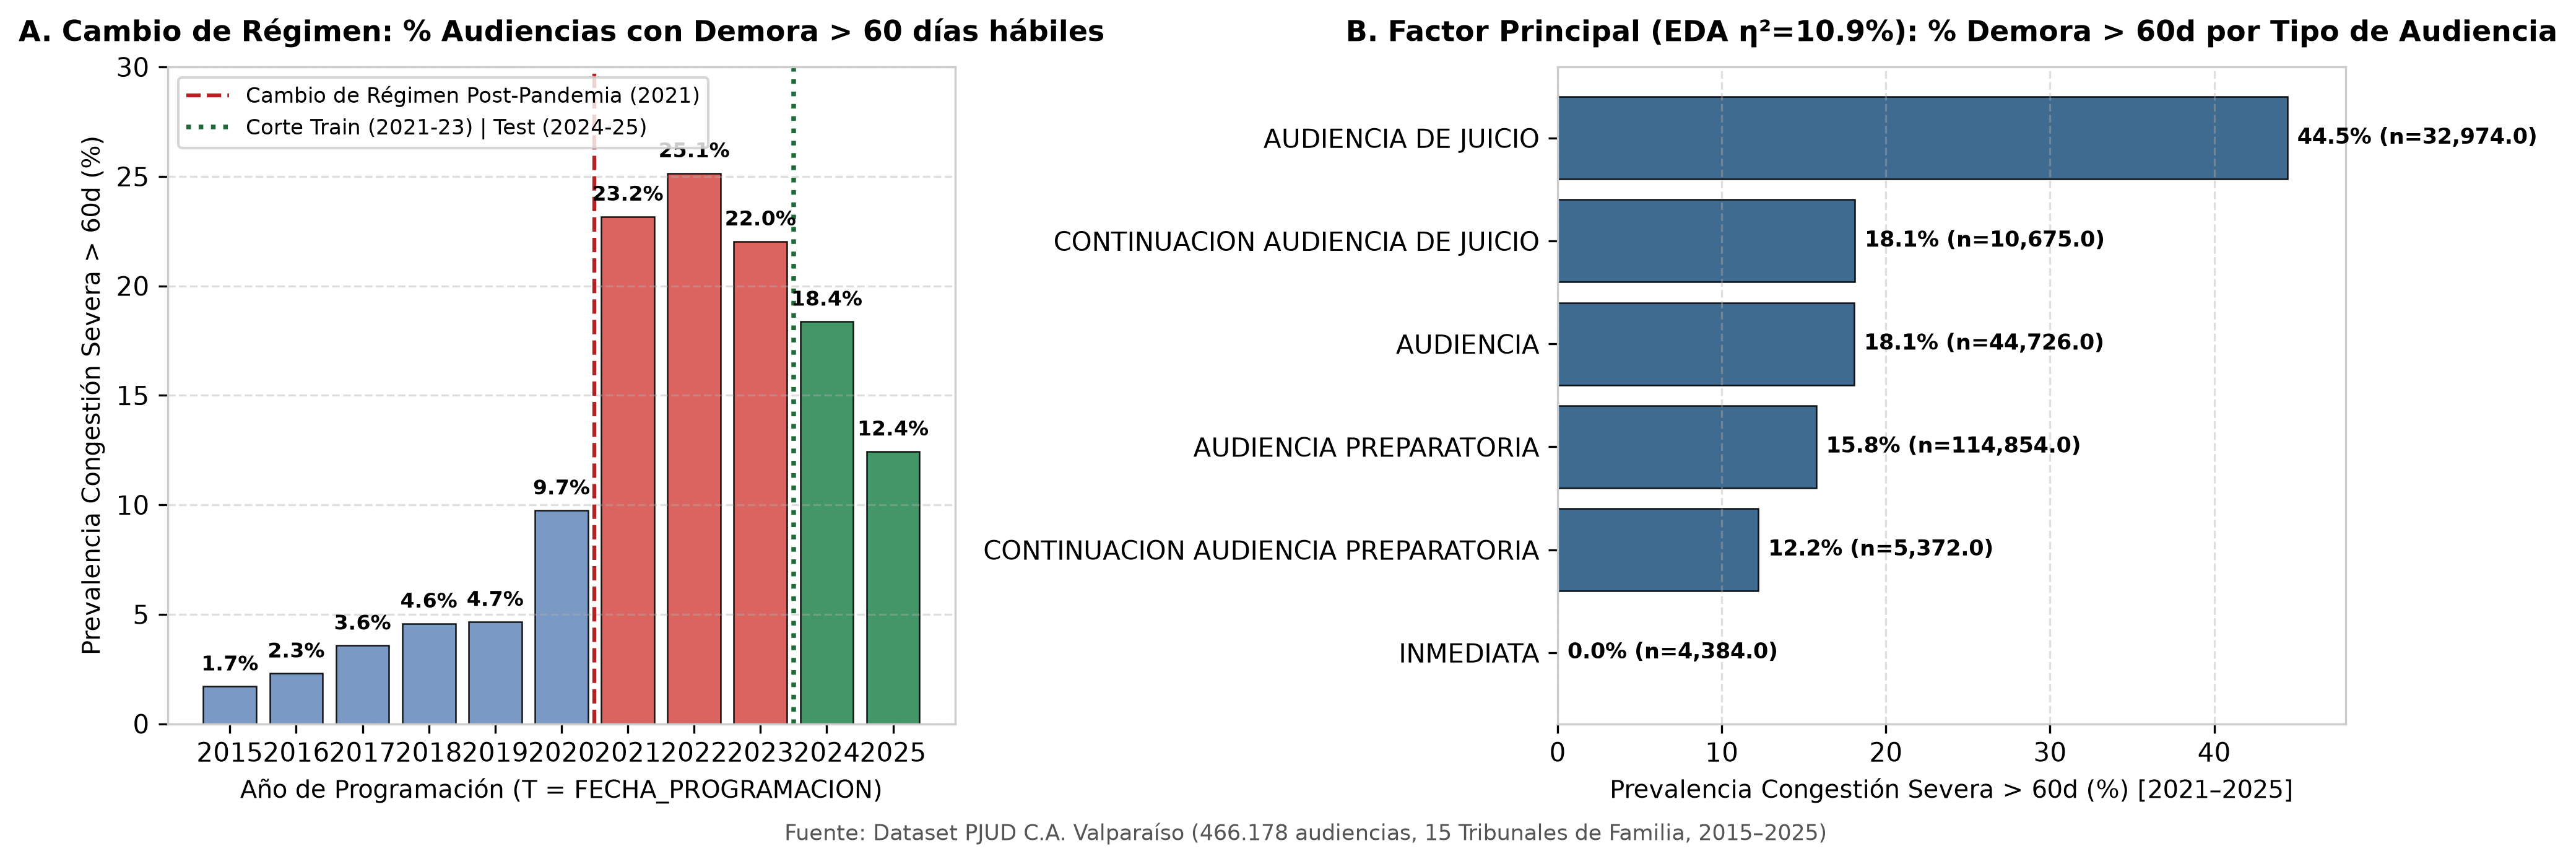

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from IPython.display import Image, display

BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG_DIR = BASE_DIR / 'reports' / 'figures_avance3'
with open(FIG_DIR / 'avance3_metrics_summary.json', 'r', encoding='utf-8') as f:
    summary = json.load(f)

print(f"Total audiencias auditadas: {summary['dataset_total_rows']:,} ({summary['dataset_total_cases']:,} causas únicas RIT)")
print(f"Train Régimen Vigente (2021-2023): {summary['train_recent_rows']:,} filas | Prevalencia Y=1: {summary['train_recent_prev']:.4f}")
print(f"Test Out-of-Time (2024-2025):      {summary['test_rows']:,} filas | Prevalencia Y=1: {summary['test_prev']:.4f}")
display(Image(filename=str(FIG_DIR / 'fig01_eda_regimen_y_audiencia.png')))

## 2. Validación Cruzada Estratificada (5-Fold `StratifiedKFold`) y Sensibilidad al Cambio de Régimen
Siguiendo el protocolo del **Taller 6**:
1. Separamos y resguardamos el conjunto de prueba futuro (`2024–2025`, $n = 83.410$).
2. En el conjunto de entrenamiento (`2021–2023`, $n = 130.057$), comparamos las familias de modelos usando `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` para preservar la prevalencia de la clase minoritaria ($23,43\%$) en cada fold.
3. Reportamos media ($M_{CV}$) y desviación estándar muestral ($s_{CV}$ con `ddof=1`).
4. Adicionalmente, demostramos empíricamente por qué entrenar en el **régimen post-pandemia (2021–2023)** supera ampliamente a entrenar con toda la serie **2015–2023** (donde la baja prevalencia pre-2020 de $1,7\%\text{–}4,7\%$ introduce un severo sesgo de subpredicción).

                     ROC-AUC Medio (CV)  ROC-AUC s_CV (ddof=1)  AP Media (CV)  AP s_CV (ddof=1)  Recall Medio @0.50  F1 Medio @0.50
Modelo                                                                                                                             
Dummy Basal                      0.5000                 0.0000         0.2343            0.0000              0.0000          0.0000
Regresión Logística              0.8286                 0.0035         0.5775            0.0048              0.3747          0.4725
Random Forest                    0.8705                 0.0024         0.6659            0.0037              0.3659          0.4890
XGBoost                          0.8829                 0.0020         0.6857            0.0040              0.5070          0.5862
CatBoost                         0.8834                 0.0023         0.6860            0.0055              0.5094          0.5879


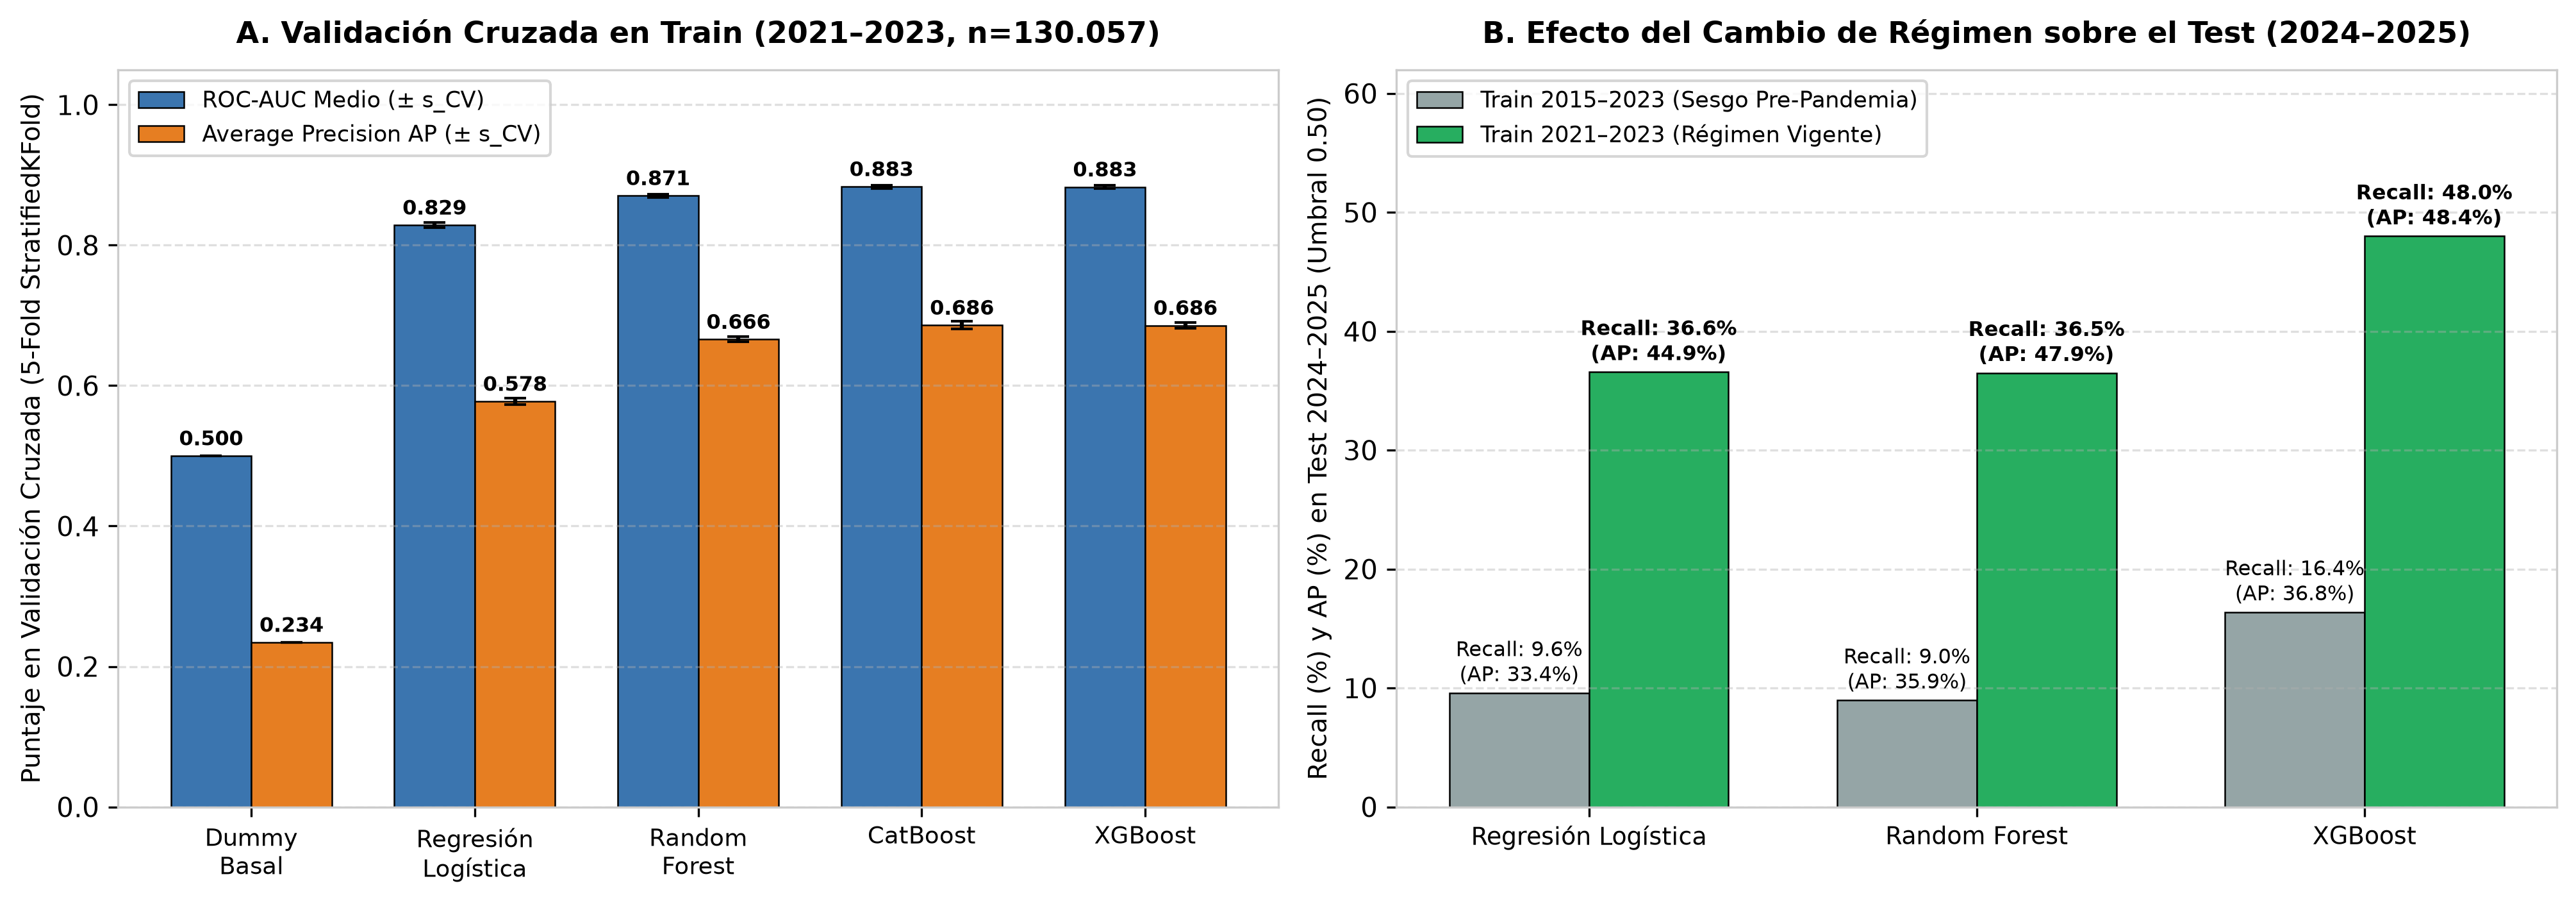

In [2]:
tabla_cv = pd.DataFrame([
    {
        'Modelo': k,
        'ROC-AUC Medio (CV)': v['ROC_AUC_mean'],
        'ROC-AUC s_CV (ddof=1)': v['ROC_AUC_std'],
        'AP Media (CV)': v['AP_mean'],
        'AP s_CV (ddof=1)': v['AP_std'],
        'Recall Medio @0.50': v['Recall_mean'],
        'F1 Medio @0.50': v['F1_mean'],
    }
    for k, v in summary['cv_results'].items()
]).set_index('Modelo')
display(tabla_cv.round(4))
display(Image(filename=str(FIG_DIR / 'fig02_validacion_cruzada_y_regimen.png')))

## 3. Rendimiento Comparado en Test (2024–2025), Curvas ROC/PR, Umbral y Bootstrap ($B=500$)
- **Diagnóstico Train vs. Test:** El modelo `XGBoost` presenta un `ROC-AUC` de `0.8869` en Train y `0.8600` en Test (diferencia de apenas `0.0269`), descartando sobreajuste severo.
- **Calibración del Umbral Operativo ($0.50 \rightarrow 0.35$):** Dado que en un estudio jurídico un **Falso Negativo** (no prever una espera $> 60$ días) es mucho más costoso que un **Falso Positivo** (preparar prueba con anticipación), calibramos el umbral a `0.35`, elevando el **Recall en Test de 48,6% a 67,9%** y mejorando el **F1-Score de 0,497 a 0,510**.
- **Bootstrap en Test ($B = 500$ réplicas con reemplazo):** Con el modelo fijo entrenado en `Train`, remuestreamos pares `(y_test, proba_test)` para cuantificar la incertidumbre muestral del conjunto de prueba.

                     Train ROC-AUC  Test ROC-AUC  Test AP  Acc @0.50  Prec @0.50  Recall @0.50  F1 @0.50  Prec @0.35  Recall @0.35  F1 @0.35
Algoritmo                                                                                                                                   
Dummy Basal                 0.5000        0.5000   0.1559     0.8441      0.0000        0.0000    0.0000      0.0000        0.0000    0.0000
Regresión Logística         0.8290        0.8265   0.4493     0.8372      0.4713        0.3658    0.4119      0.4353        0.5724    0.4945
Random Forest               0.8738        0.8518   0.4795     0.8541      0.5478        0.3650    0.4381      0.4168        0.6041    0.4932
XGBoost                     0.8894        0.8605   0.4843     0.8460      0.5065        0.4799    0.4928      0.4052        0.6752    0.5065
CatBoost                    0.8880        0.8608   0.4801     0.8468      0.5089        0.4809    0.4945      0.4048        0.6718    0.5052


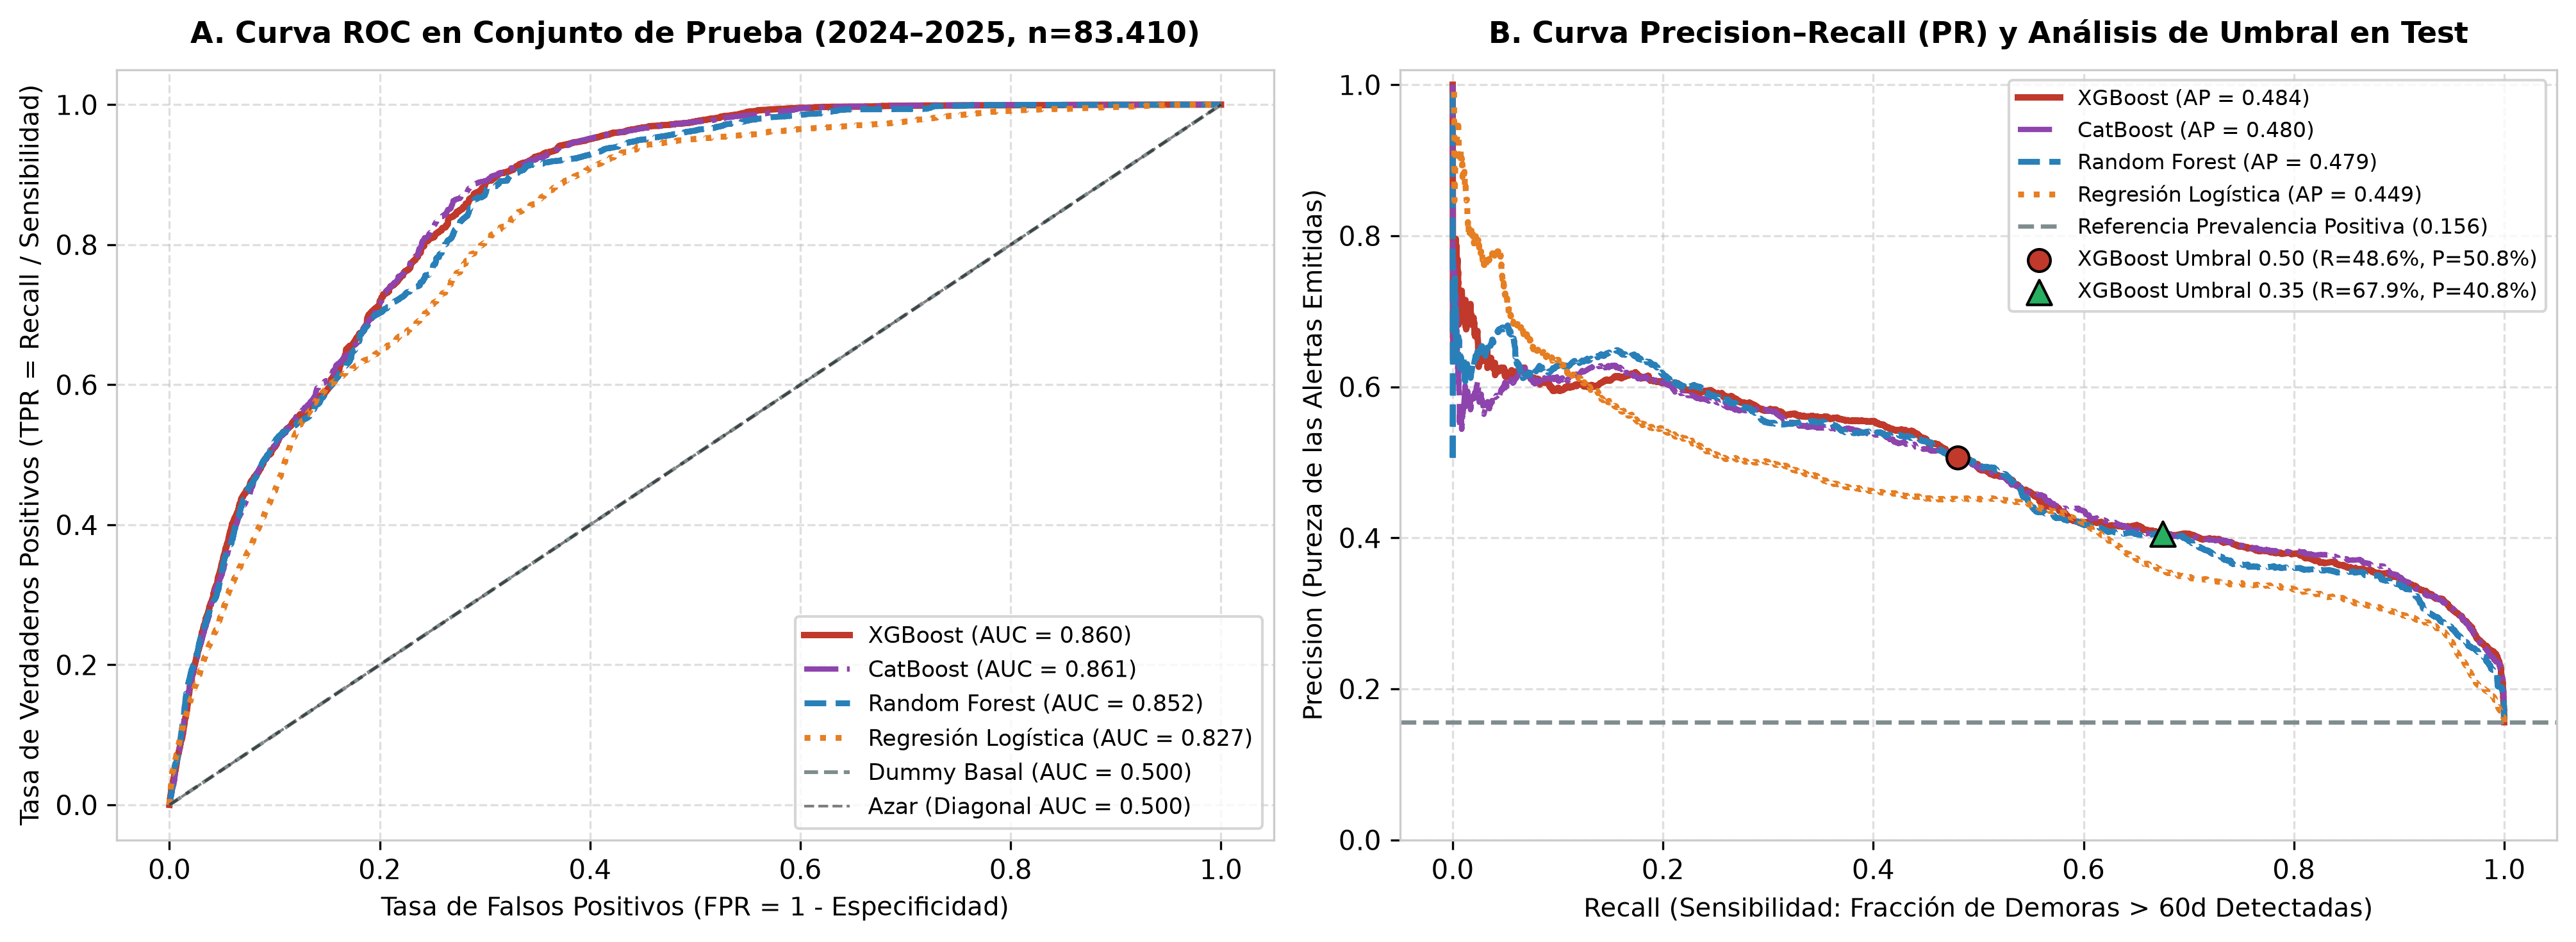

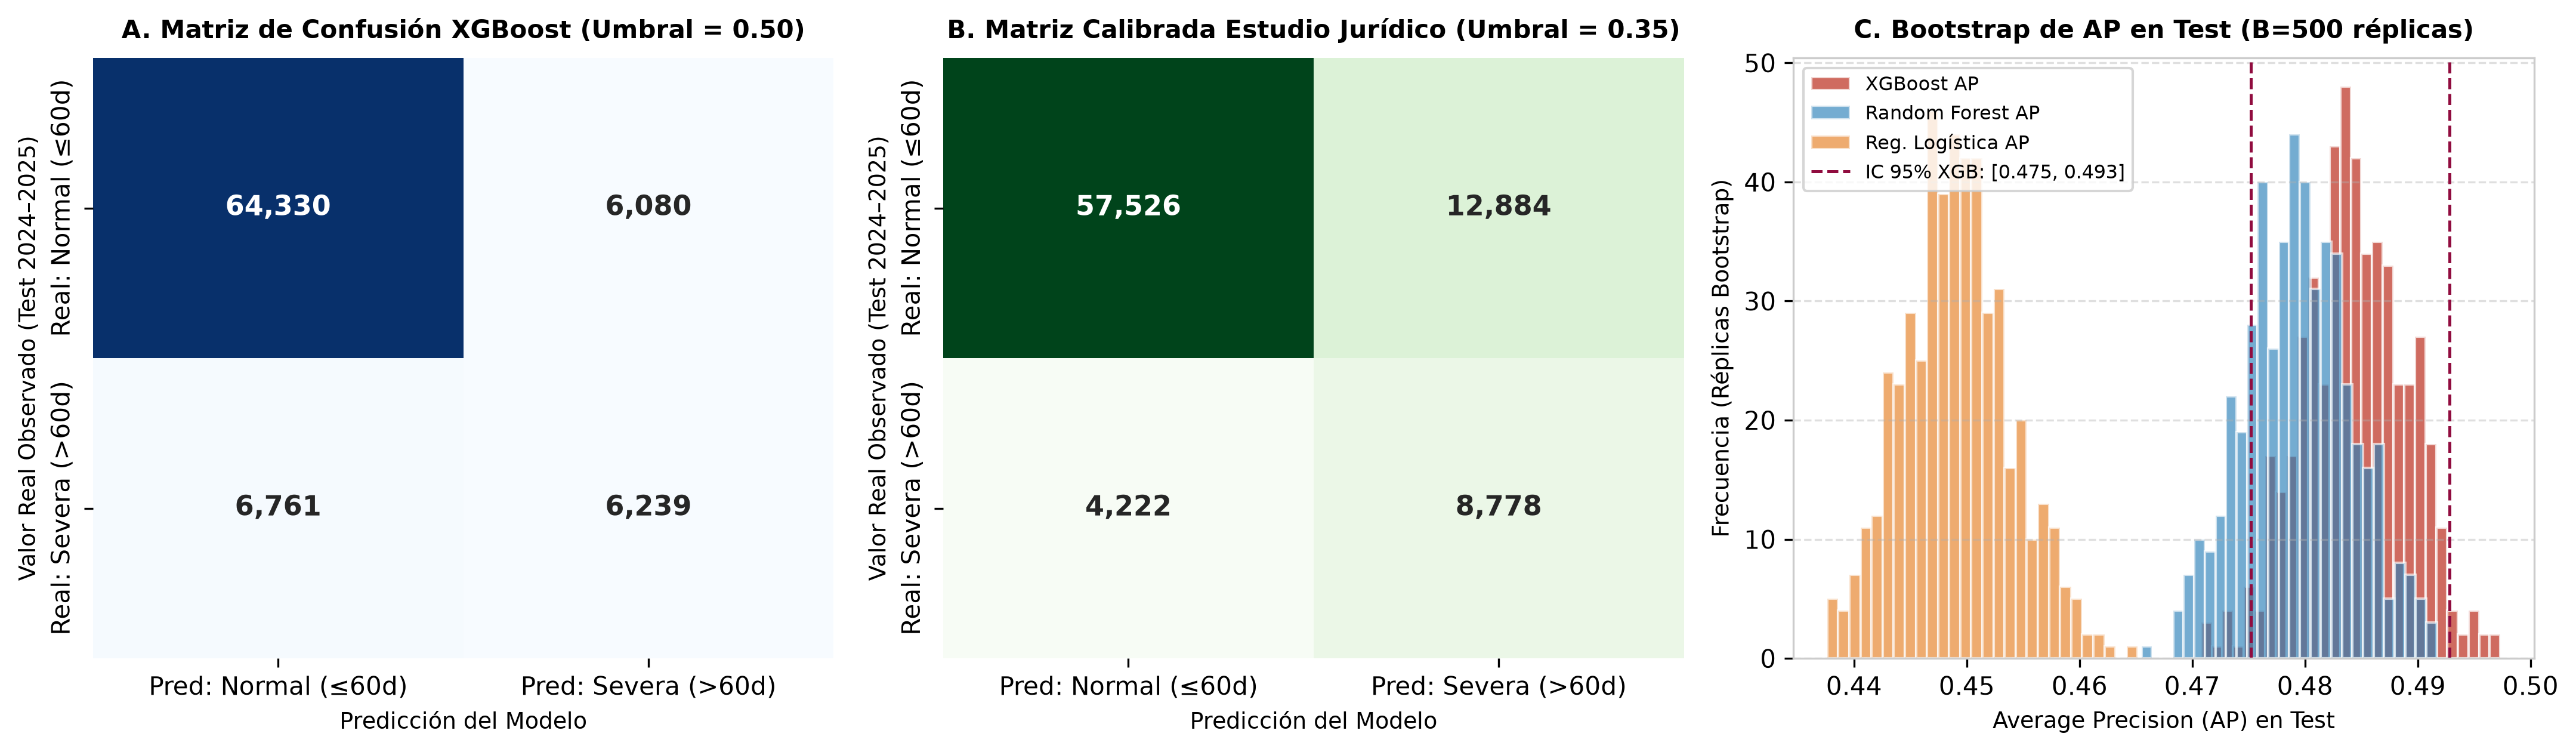

In [3]:
tabla_test = pd.DataFrame([
    {
        'Algoritmo': k,
        'Train ROC-AUC': v['train_roc_auc'],
        'Test ROC-AUC': v['test_roc_auc'],
        'Test AP': v['test_ap'],
        'Acc @0.50': v['test_acc_50'],
        'Prec @0.50': v['test_prec_50'],
        'Recall @0.50': v['test_rec_50'],
        'F1 @0.50': v['test_f1_50'],
        'Prec @0.35': v['test_prec_35'],
        'Recall @0.35': v['test_rec_35'],
        'F1 @0.35': v['test_f1_35'],
    }
    for k, v in summary['test_results'].items()
]).set_index('Algoritmo')
display(tabla_test.round(4))
display(Image(filename=str(FIG_DIR / 'fig03_curvas_roc_y_pr_test.png')))
display(Image(filename=str(FIG_DIR / 'fig04_matrices_confusion_y_bootstrap.png')))

## 4. Explicabilidad Global (`shap.plots.beeswarm`) y Local (`shap.plots.waterfall`)
- **Escala declarada:** Los valores SHAP del `TreeExplainer` sobre `XGBoost` están expresados en **log-odds** (donde $\text{probabilidad} = \frac{1}{1 + e^{-f(x)}}$).
- **Advertencia de No Causalidad (Taller 6):** Que una variable exhiba alta importancia SHAP indica cuánto influye en la predicción del modelo dado el conjunto de variables correlacionadas, pero no prueba un efecto causal directo ante una intervención.
- **3 Casos Locales Analizados en Test:**
  1. **Caso 1 (Verdadero Positivo — Acierto Crítico):** Audiencia con espera severa real correctamente alertada.
  2. **Caso 2 (Verdadero Negativo — Vía Rápida):** Audiencia ágil correctamente descartada.
  3. **Caso 3 (Falso Negativo — Error Forense):** Audiencia Preparatoria inicial que demoró $> 75$ días hábiles pese a tener atributos estructurales de baja demora, evidenciando el rol de factores externos no registrados (peritajes SML/DAM o notificaciones).

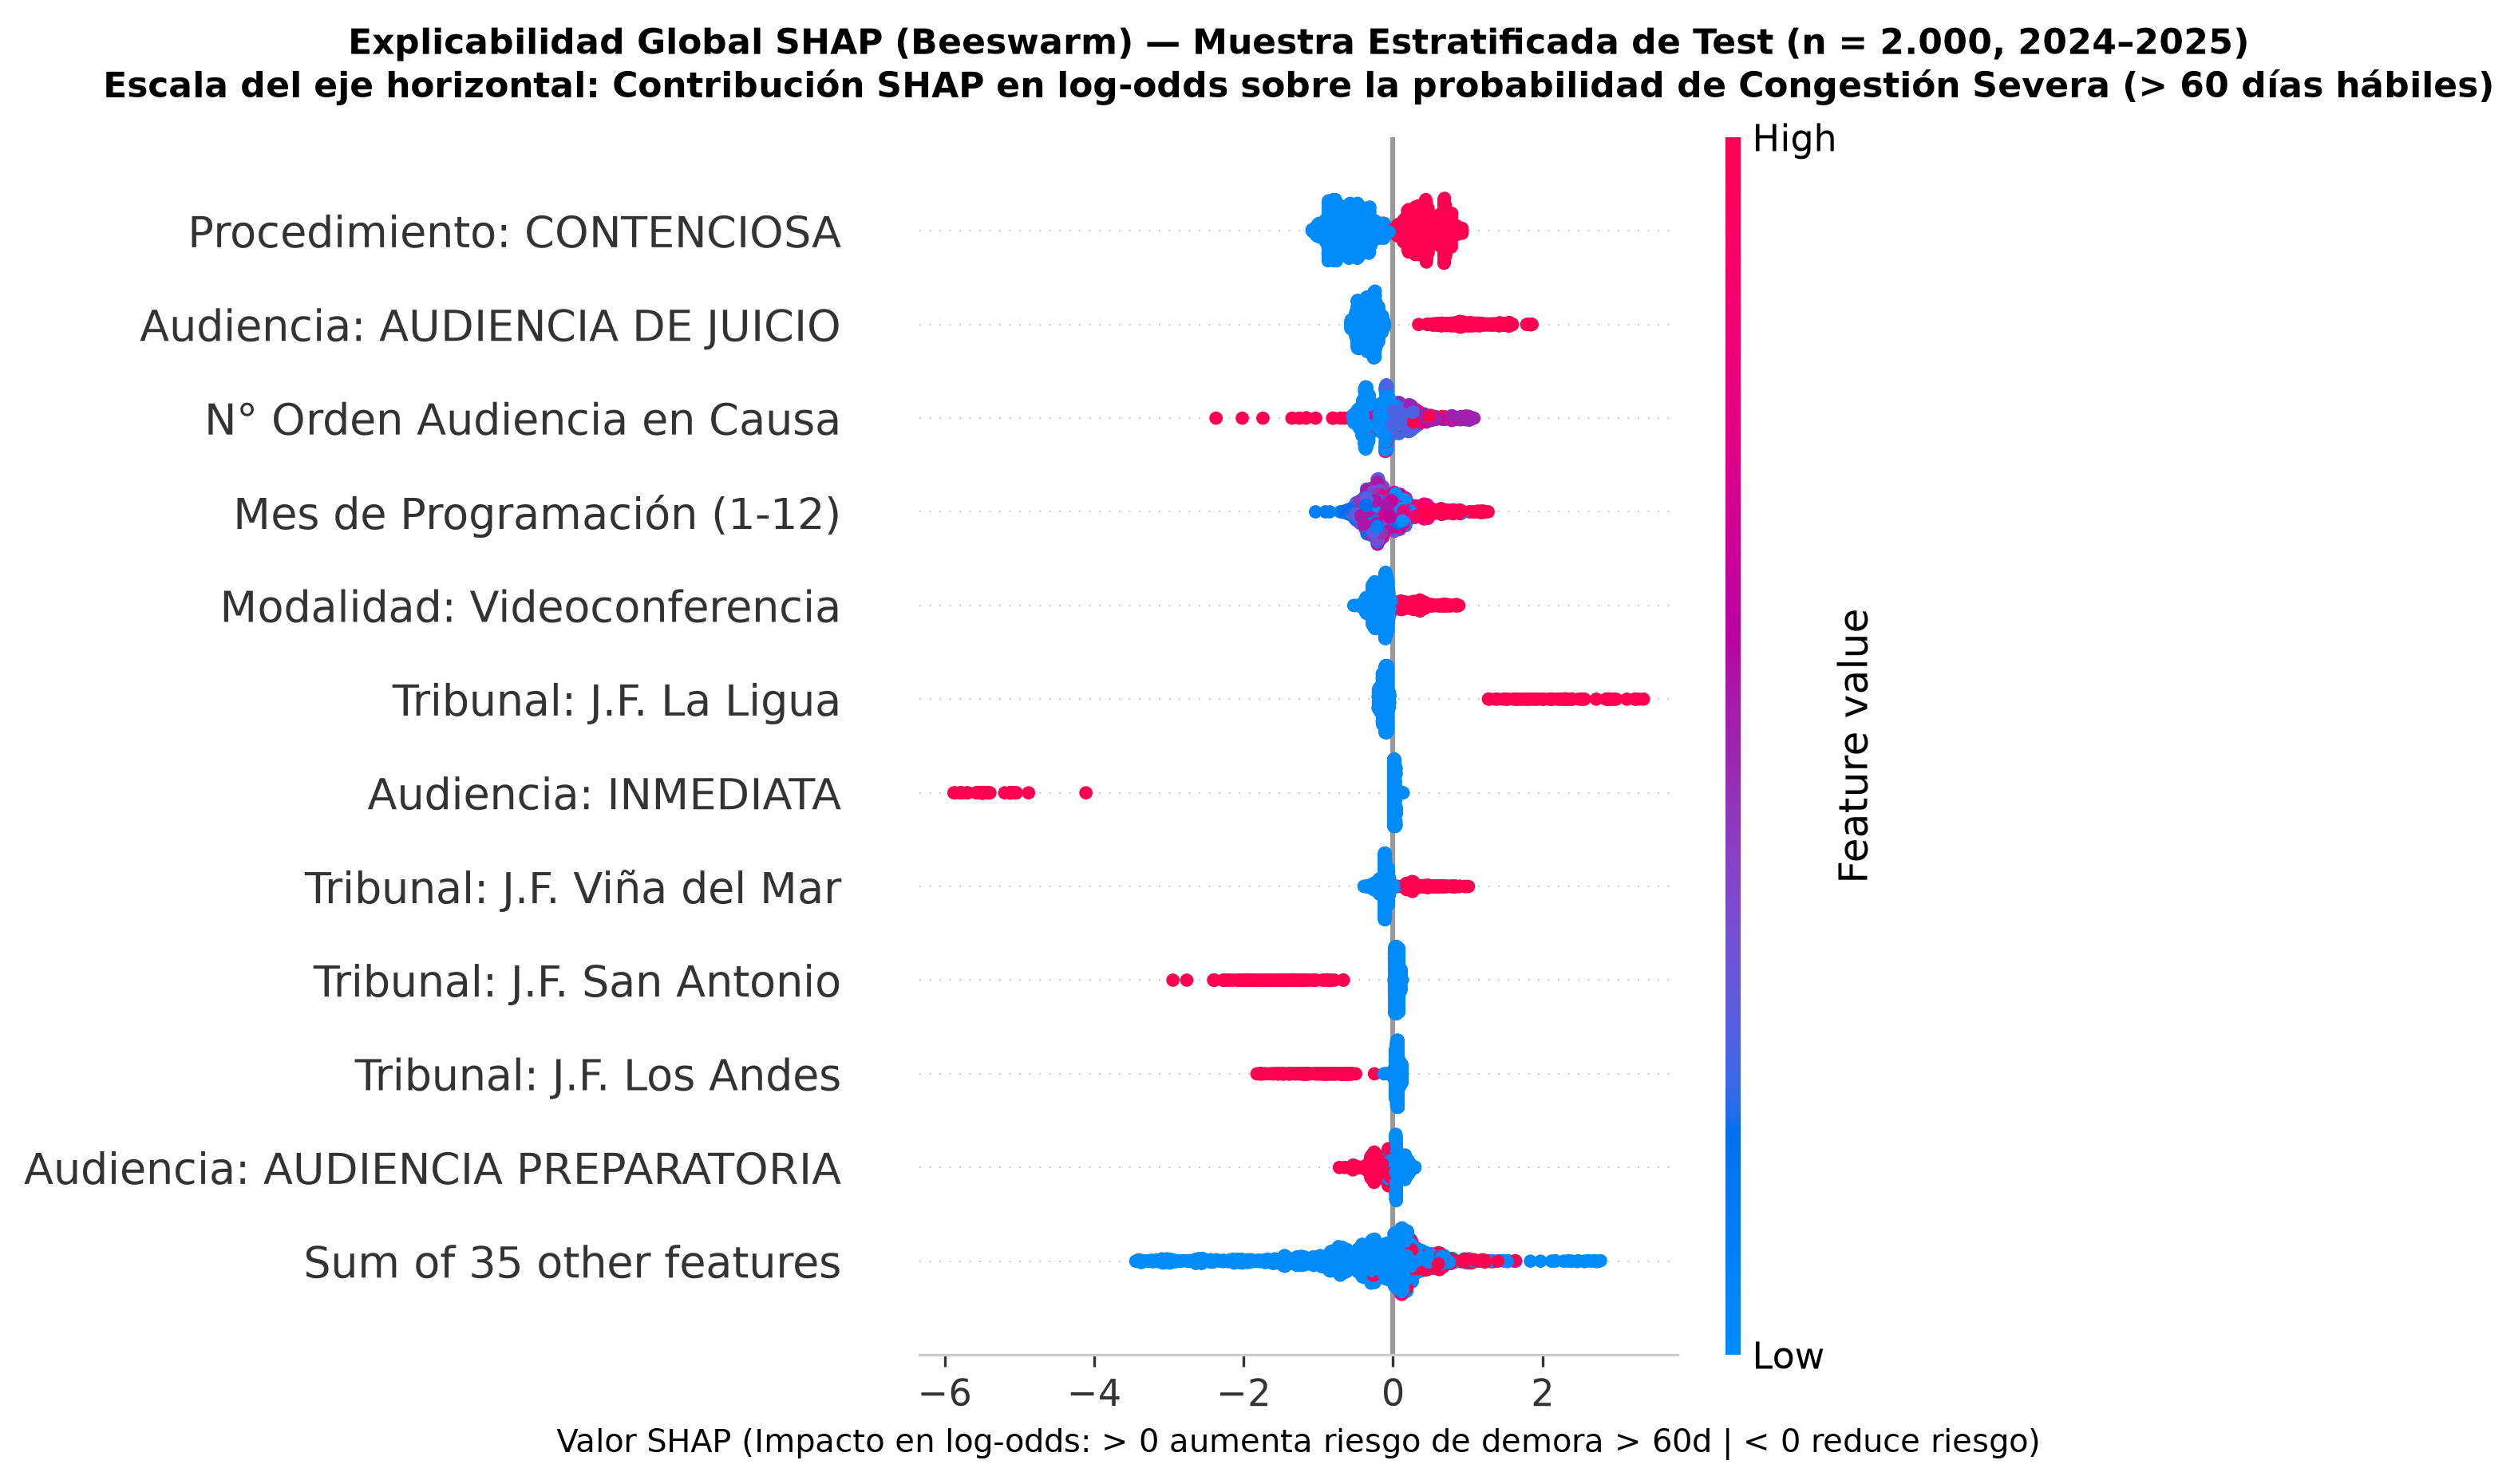

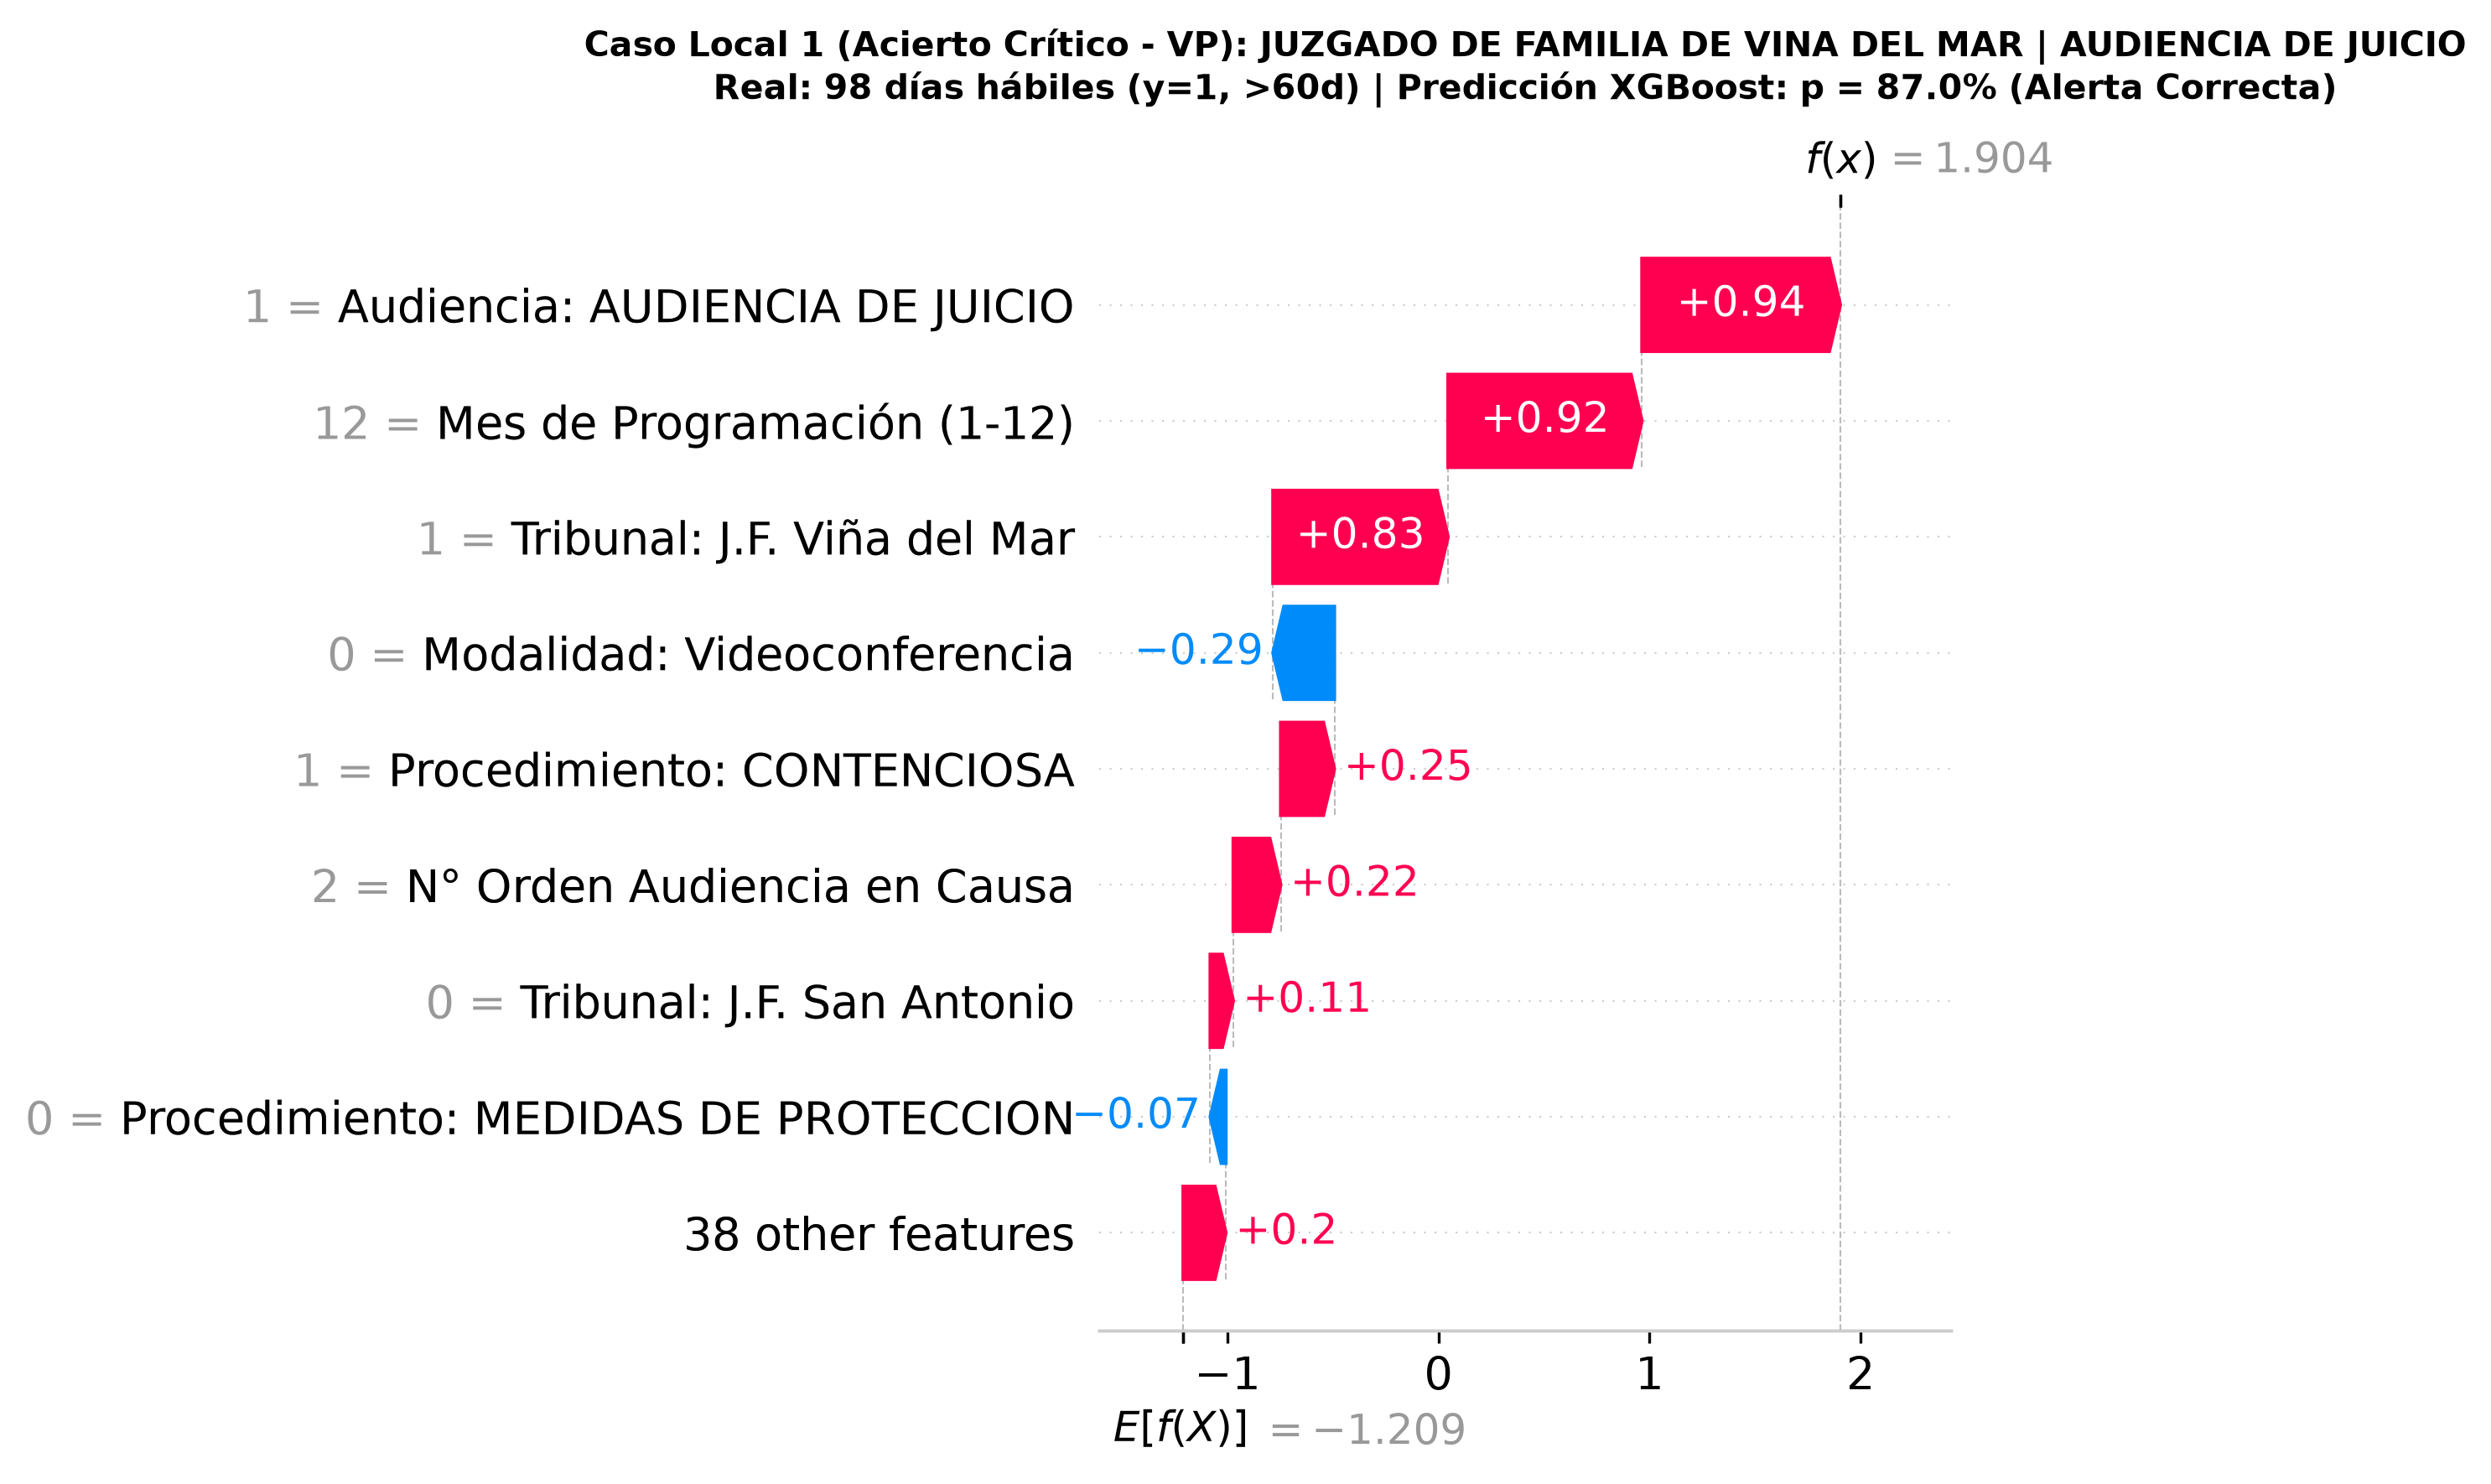

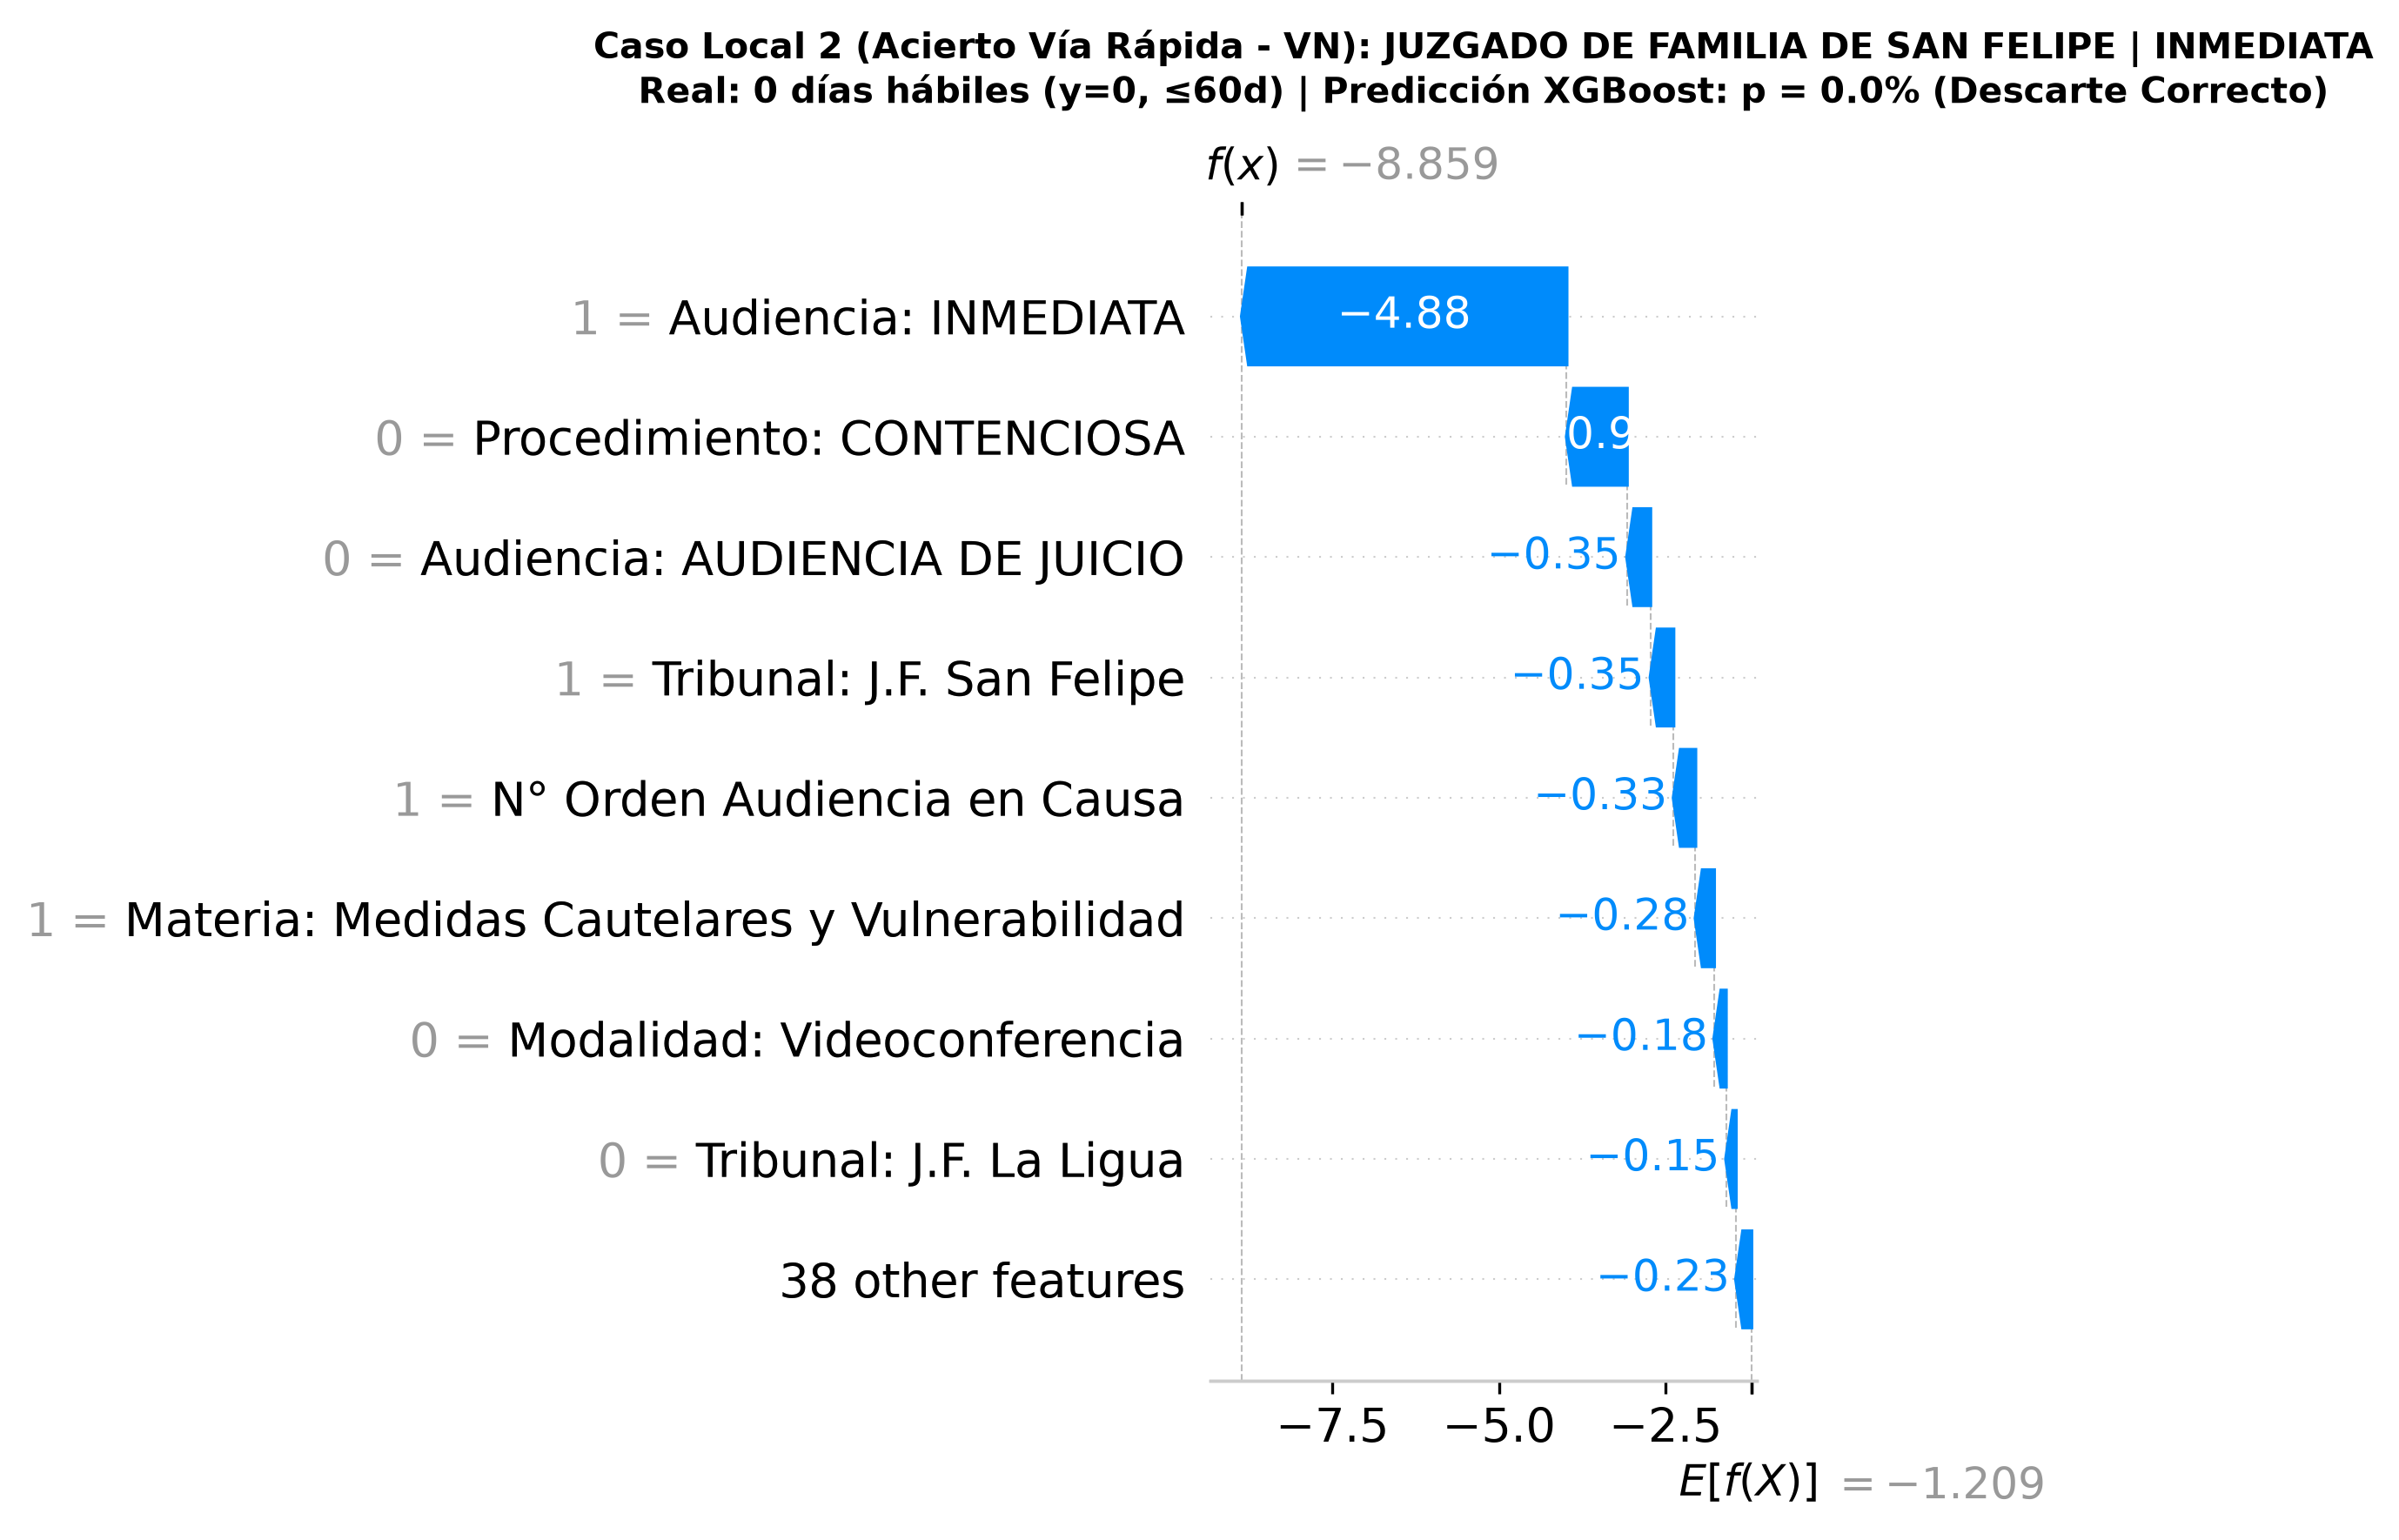

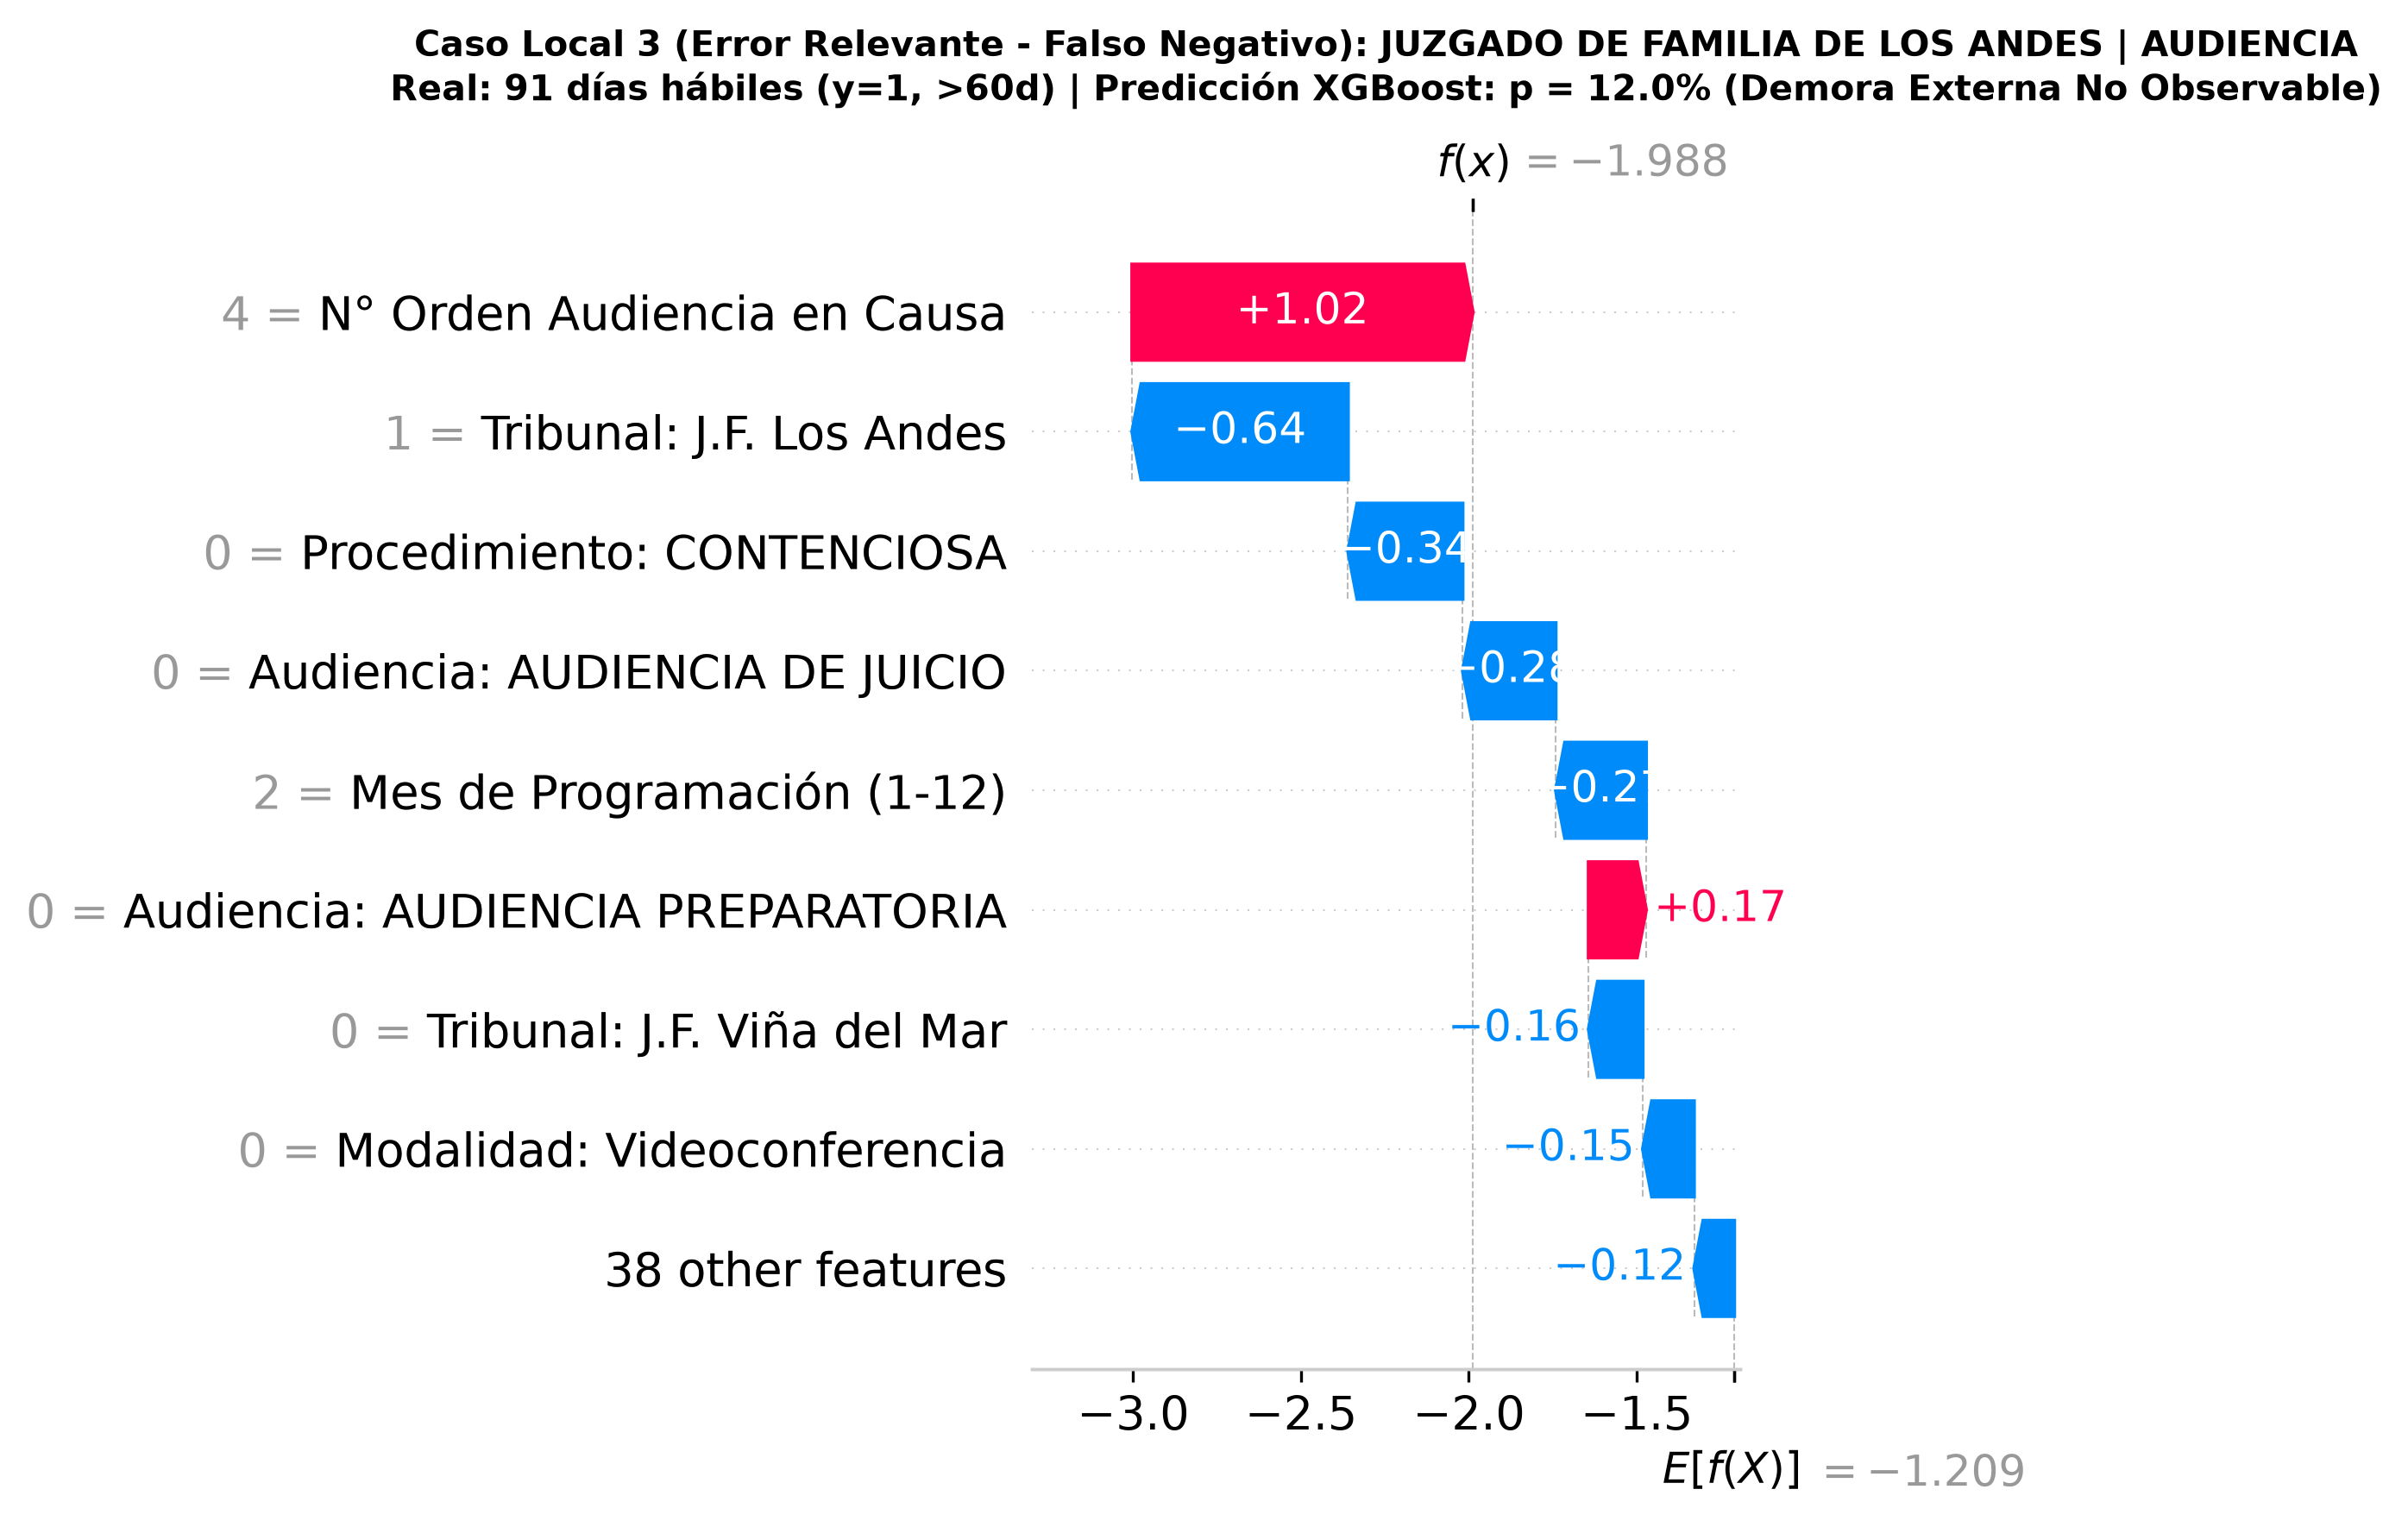

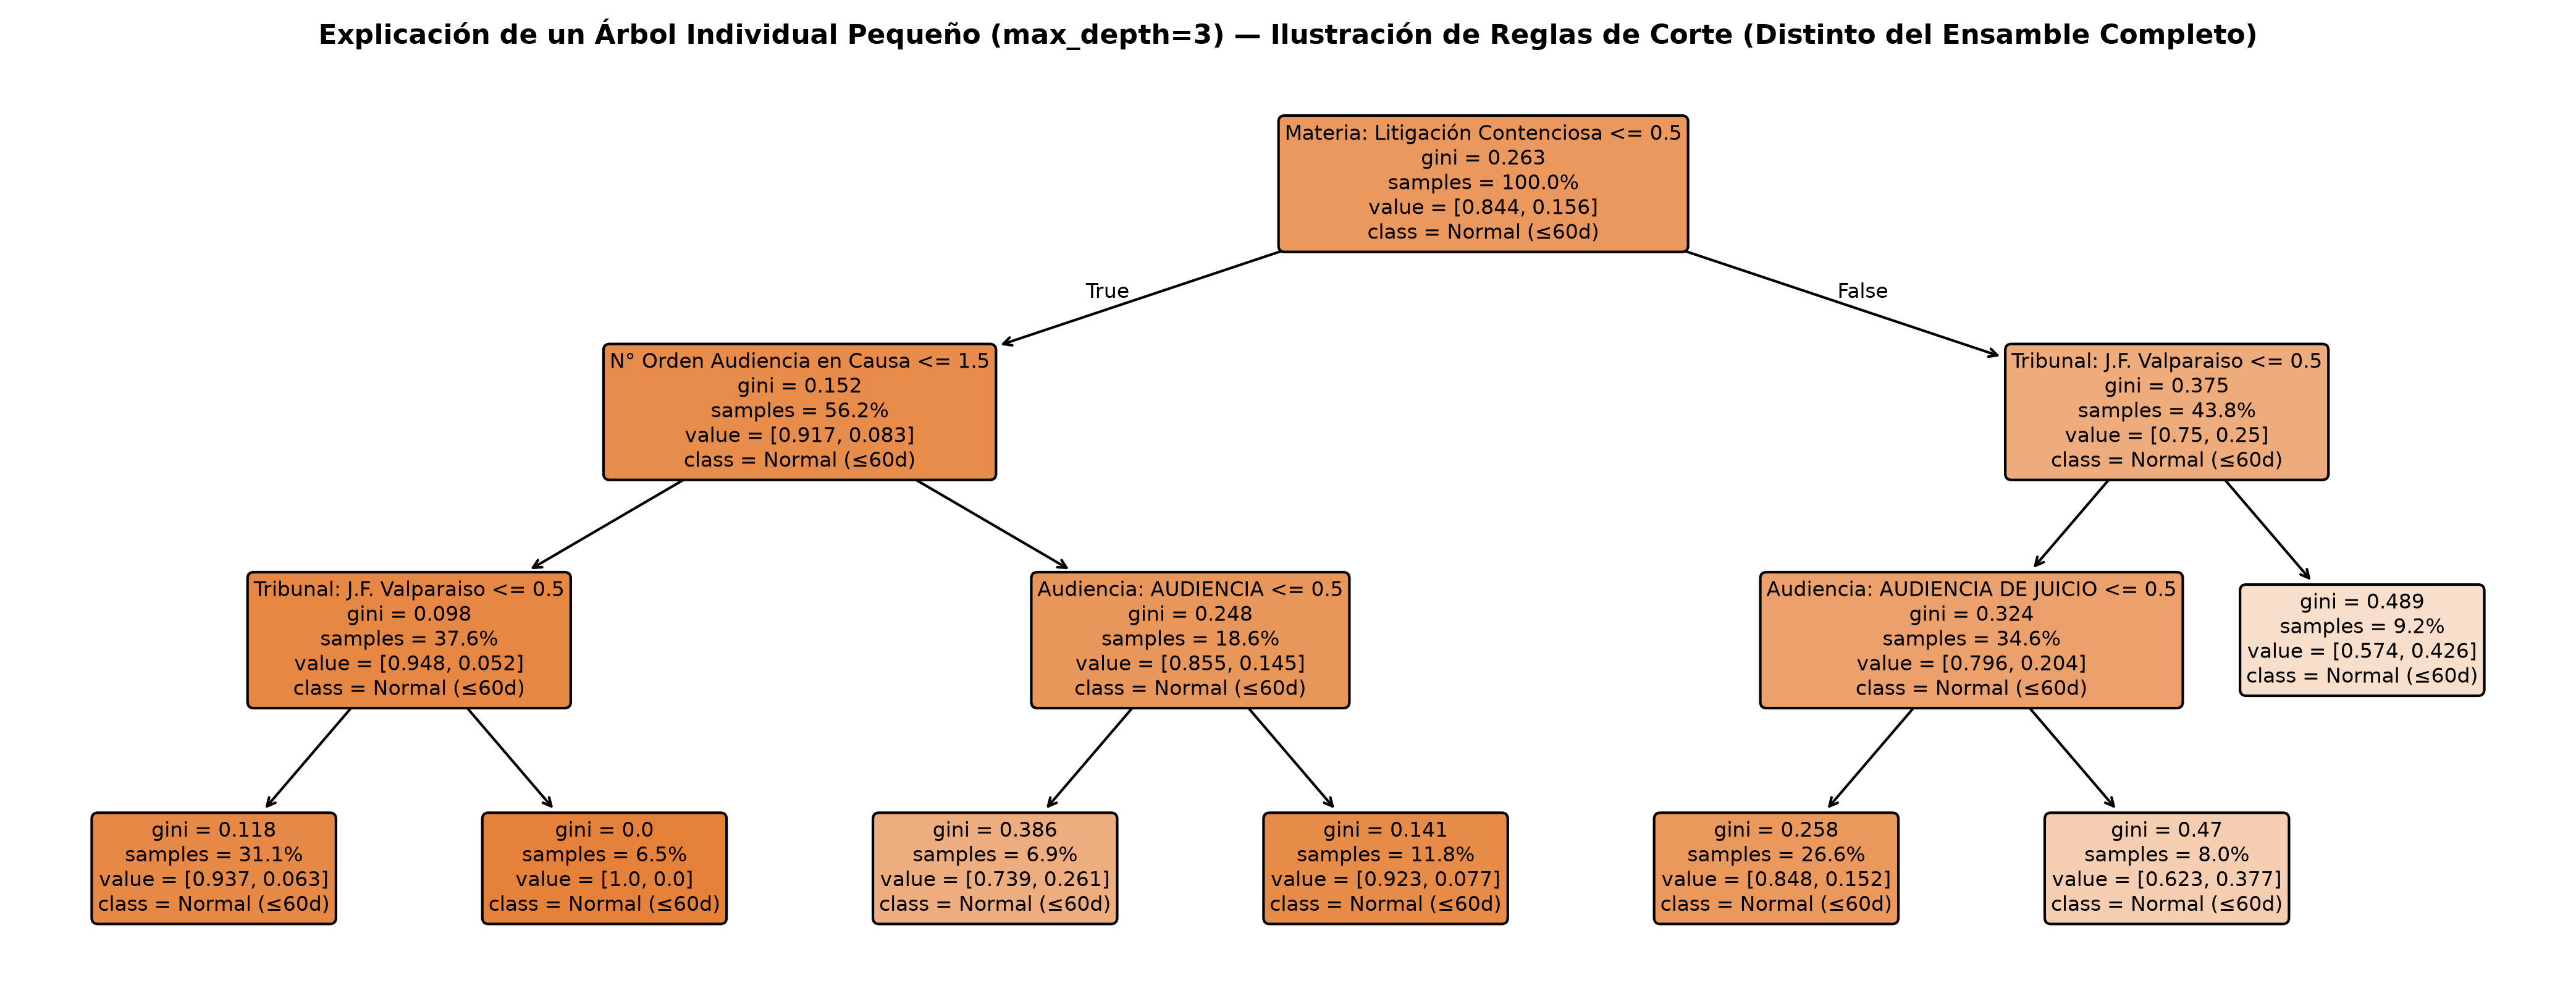

In [4]:
display(Image(filename=str(FIG_DIR / 'fig05_shap_beeswarm_global.png')))
display(Image(filename=str(FIG_DIR / 'fig06a_shap_waterfall_caso1_vp.png')))
display(Image(filename=str(FIG_DIR / 'fig06b_shap_waterfall_caso2_vn.png')))
display(Image(filename=str(FIG_DIR / 'fig06c_shap_waterfall_caso3_fn.png')))
display(Image(filename=str(FIG_DIR / 'fig07_arbol_decision_interpretable.png')))